Build A Basic Chatbot With Langgraph(GRAPH API)

In [1]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    # Messages have the type "list". The 'add_messages' function in the annotation defines how this state key should be updated.
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages: Annotated[list, add_messages]

graph_builder= StateGraph(State)   


In [3]:
graph_builder

In [4]:
import os
from dotenv import load_dotenv

load_dotenv()

True

In [5]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="qwen/qwen3.8-27b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'Qwen3.8 27B', 'status': 'beta', 'release_date': '2026-08-14', 'last_updated': '2026-08-14', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000172BFCE52B0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000172BFCE5D30>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
## node functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [7]:
graph_builder=StateGraph(State)

##creating node
graph_builder.add_node("chatbot", chatbot)

##creating edges
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)

##compile the graph
graph=graph_builder.compile()


In [8]:
graph.invoke({"messages":"Hi"})

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='6113b7fa-5e5a-4156-80a5-353cd2555659'),
  AIMessage(content='Hello! How can I help you today?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 13, 'total_tokens': 23, 'completion_time': 0.021956673, 'completion_tokens_details': None, 'prompt_time': 0.000889897, 'prompt_tokens_details': None, 'queue_time': 0.156670558, 'total_time': 0.02284657}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20200-d0b0-70b4-b6c0-bfe8c06dc504-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_tokens': 10, 'total_tokens': 23})]}

In [10]:
import os

os.environ["TAVILY_API_KEY"] = "TAVILY_API_KEY"

In [11]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_resukts=2)
tool.invoke("what is langghraph?")


{'error': ValueError('Error 401: Unauthorized: missing or invalid API key.')}

In [31]:
## custom function
def multiply(a:int, b:int):
    """Multiply a and b
    
    Args:
        a (int): first int
        b (int): second int
        
    returns:
        int: output int
    """
    return a * b

In [20]:
tools=[tool, multiply]

In [21]:
llm_with_tool=llm.bind_tools(tools)

In [22]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'Qwen3.8 27B', 'status': 'beta', 'release_date': '2026-08-14', 'last_updated': '2026-08-14', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000172BFCE52B0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000172BFCE5D30>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine op

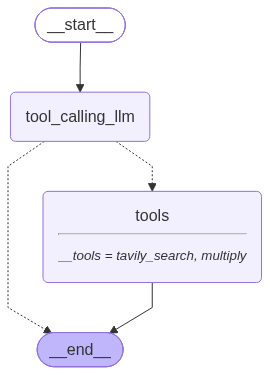

In [24]:
## State graph with tools
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from IPython.display import Image, display

##node defination
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

##graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## add edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
    )
builder.add_edge("tools", END)

##compile the graph
graph=builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))


In [33]:
response = graph.invoke({"messages": "What is the recent AI news in the world?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent AI news in the world?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (dzy1s7tqe)
 Call ID: dzy1s7tqe
  Args:
    end_date: None
    exclude_domains: []
    include_domains: []
    include_images: False
    query: latest AI news
    search_depth: None
    start_date: None
    time_range: None
    topic: None
================================= Tool Message =================================
Name: tavily_search

{'error': ValueError('Error 401: Unauthorized: missing or invalid API key.')}
================================== Ai Message ==================================

I'm sorry, but I wasn't able to retrieve the latest AI news because the search tool returned an authentication error (missing or invalid API key).

However, I can offer some general guidance:

- **Check major tech news sources** like Reuters, TechCrunch, The Verge, 

In [30]:
response

{'messages': [HumanMessage(content='What is the recent AI news in the world?', additional_kwargs={}, response_metadata={}, id='ddd9a195-ccf9-4f36-a124-0820f2e5c88e'),
  AIMessage(content='The recent AI news can be summarized as follows:\n\n1. **U.S. Government Takes Control of Anthropic\'s Top AI Models**: The U.S. government has taken control of Anthropic\'s frontier AI models in a first-of-its-kind action, though the company continues to operate normally. This move is part of a broader effort to create a "trusted access" channel for AI systems and has raised concerns among privacy experts about potential government overreach.\n\n2. **New AI Threats to Cybersecurity**: The 2025 AI Threats Report highlights a rise in malicious AI use, including "prompt injection" attacks where adversaries manipulate AI systems to bypass safeguards and steal data.\n\n3. **AI in Medical Research**: A landmark study published in *Nature* by researchers at the University of Chicago\'s Pritzker School of Mo

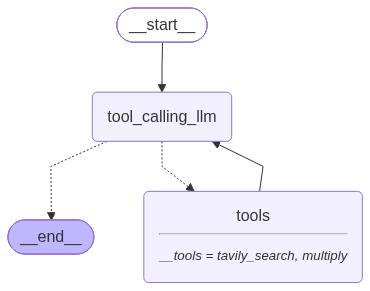

In [25]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from IPython.display import Image, display

##node defination
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

##graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## add edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
     tools_condition
)
builder.add_edge("tools", "tool_calling_llm")
    
##compile the graph
graph=builder.compile()
    
display(Image(graph.get_graph().draw_mermaid_png()))

In [32]:
response=graph.invoke({"messages":" what is 5 multiplied by 5?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

 what is 5 multiplied by 5?
================================== Ai Message ==================================
Tool Calls:
  multiply (bvghxz2hm)
 Call ID: bvghxz2hm
  Args:
    a: 5
    b: 5
================================= Tool Message =================================
Name: multiply

null
================================== Ai Message ==================================

The result of 5 multiplied by 5 is **25**.


In [35]:
response=graph.invoke({"messages":" Give me the recent ai news and then multiply 5 by 5?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

 Give me the recent ai news and then multiply 5 by 5?
================================== Ai Message ==================================

Here are two separate requests in your question, so I'll handle them independently:

1. **Recent AI news** — Let me search for that.
2. **Multiply 5 by 5** — This is straightforward: 5 × 5 = **25**.

Let me fetch the AI news for you:
Tool Calls:
  tavily_search (gbc43983y)
 Call ID: gbc43983y
  Args:
    end_date: None
    exclude_domains: []
    include_domains: []
    include_images: False
    query: latest AI news
    search_depth: None
    start_date: None
    time_range: None
    topic: None
================================= Tool Message =================================
Name: tavily_search

{'error': ValueError('Error 401: Unauthorized: missing or invalid API key.')}
================================== Ai Message ==================================

The news search to

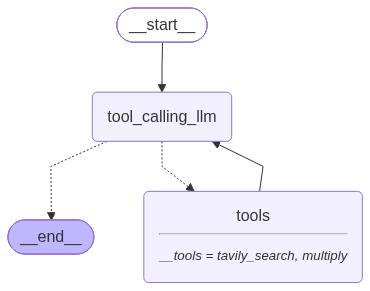

In [42]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from IPython.display import Image, display
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

##node defination
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

##graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## add edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
     tools_condition
)
builder.add_edge("tools", "tool_calling_llm")
    
##compile the graph
graph = builder.compile(checkpointer=memory)
    
display(Image(graph.get_graph().draw_mermaid_png()))

In [43]:
config = {"configurable":{"thread_id": "1"}}

response = graph.invoke({"messages":"Hi my name is Laika"}, config=config)

response

{'messages': [HumanMessage(content='Hi my name is Laika', additional_kwargs={}, response_metadata={}, id='af73179d-b794-4671-98c8-b73f40c997c0'),
  AIMessage(content="Hello Laika! It's nice to meet you. How can I help you today?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 19, 'prompt_tokens': 1911, 'total_tokens': 1930, 'completion_time': 0.042052926, 'completion_tokens_details': None, 'prompt_time': 0.133612077, 'prompt_tokens_details': None, 'queue_time': 0.096719493, 'total_time': 0.175665003}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20654-114b-747f-8a73-acb1f5d8e45a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1911, 'output_tokens': 19, 'total_tokens': 1930})]}

In [44]:
response['messages'][-1].content

"Hello Laika! It's nice to meet you. How can I help you today?"

In [45]:
response = graph.invoke({"messages":"Hey what is my name"}, config=config)

print(response['messages'][-1].content)

Your name is Laika.
